# Comparing tTEM with tTEM

In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion  import *

In [18]:
tx = Loop.square(3)
rx = Receiver(x=13)

In [19]:
tgates = torch.logspace(-5, -3, 21)

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

device = torch.device('cpu')
fwr = Forward(tx, rx, tgates, Waveform.example(), recfilters, tolerance=1e-8)

In [20]:
res = np.array([40, 200, 40])
sigma = torch.from_numpy(1./res)
thick = torch.tensor([20, 20])
dbdt = fwr(sigma, thick)
dbdt_err = compute_relstd(fwr.times, dbdt, moment=tx.area*10)

m_true = FewLayerModel(sigma, thick)

cmd_smooth = SmoothModel.starting_model(31)
cmd_smooth.values[0] *= 10

dbdt_with_noise = dbdt + torch.randn(len(dbdt))*dbdt*dbdt_err

inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
rmod = inv2.invert(smoothness=100, iter_cap=20)

001	misfit:	203.67
002	misfit:	98.96
003	misfit:	63.13
004	misfit:	39.43
005	misfit:	26.86
006	misfit:	21.09
increased max step
007	misfit:	12.57
increased max step
008	misfit:	8.97
increased max step
009	misfit:	5.20
increased max step
010	misfit:	2.95
increased max step
011	misfit:	2.03
increased max step
012	misfit:	1.76
increased max step
013	misfit:	1.64
increased max step
014	misfit:	1.56
increased max step
015	misfit:	1.49
016	misfit:	1.44
017	misfit:	1.40
018	misfit:	1.38
019	misfit:	1.36
020	misfit:	1.35
reached iteration cap..
reached iteration cap..

 20


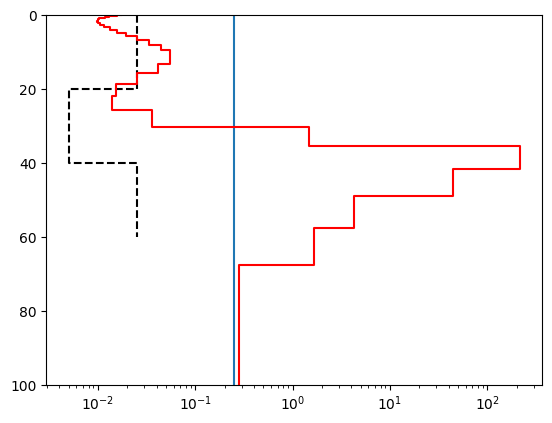

In [21]:
ax = cmd_smooth.plot()
ax = m_true.plot(ax=ax, color='k', linestyle='--')
ax = rmod.plot(ax=ax, color='r')
ax.set_ylim(100, 0)
ax.set_xscale('log')